# SVM on TF-IDF

This notebook trains an SVM model on the same TF-IDF features and train/test split as the Logistic Regression baseline. A boosted model of 200 trees cannot be read directly, so we explain it with post-hoc methods.

The explanation steps follow the course's interpretation pipeline: global importance (PFI / TreeSHAP) → feature effects (PDP) → heterogeneity (ICE / centered ICE) → individual decisions (LIME / SHAP).

## 1.Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap

import nltk
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("punkt")
nltk.download("punkt_tab")

from IPython.display import display
from sklearn.svm import SVC
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, recall_score, accuracy_score, roc_auc_score
)
from sklearn.inspection import PartialDependenceDisplay

from lime.lime_text import LimeTextExplainer
from lime.submodular_pick import SubmodularPick

from preprocessing import (
    preprocess_text, get_tfidf_features,
    get_train_test_split, select_top_k_terms, RANDOM_STATE
)

c:\Users\ADMIN\Desktop\XDS_project\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


## 2. Load Cleaned Dataset

In [2]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv")
df[["title", "text", "label", "label_encoded"]].head()

,title,text,label,label_encoded
0,Foreign Democrat final.,more tax development both store agreement lawy...,real,0
1,To offer down resource great point.,probably guess western behind likely next inve...,fake,1
2,Himself church myself carry.,them identify forward present success risk sev...,fake,1
3,You unit its should.,phone which item yard Republican safe where po...,fake,1
4,Billion believe employee summer how.,wonder myself fact difficult course forget exa...,fake,1


## 3. Text Preprocessing (NLP Pipeline)

In [3]:
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)
df[["full_text", "processed_text"]].head()

,full_text,processed_text
0,Foreign Democrat final. more tax development b...,foreign democrat final tax development store a...
1,To offer down resource great point. probably g...,offer resource great point probably guess west...
2,Himself church myself carry. them identify for...,church carry identify forward present success ...
3,You unit its should. phone which item yard Rep...,unit phone item yard republican safe police id...
4,Billion believe employee summer how. wonder my...,billion believe employee summer wonder fact di...


Quick sanity check: compare one raw vs. processed example side by side.

In [4]:
print("RAW:\n", df["full_text"].iloc[0][:300])
print("\nPROCESSED:\n", df["processed_text"].iloc[0][:300])

RAW:
 Foreign Democrat final. more tax development both store agreement lawyer hear outside continue reach difference yeah figure your power fear identify there protect security great national nothing fast story why late nearly bit cost tough since question to power almost future young conference behind a

PROCESSED:
 foreign democrat final tax development store agreement lawyer hear outside continue reach difference yeah figure power fear identify protect security great national nothing fast story late nearly bit cost tough since question power almost future young conference behind ahead building teach million b


## 4. TF-IDF Vectorization


In [5]:
X, y, tfidf = get_tfidf_features(df)
feature_names = tfidf.get_feature_names_out()

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (20000, 867)


## 5. Train/Test Split

In [6]:
X_train, X_test, y_train, y_test = get_train_test_split(X, y)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class balance:\n", y_test.value_counts(normalize=True).round(3))

Train shape: (16000, 867)
Test shape: (4000, 867)

Train class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64

Test class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64


### 5.1 Dense Arrays for the SVM

The SVM is trained and scored on dense arrays, which is much faster than sparse input for this data, and a model trained on dense data cannot be given sparse input. The TF-IDF matrix is therefore converted to a dense array here and the dense version is used from now on.

In [7]:
X_train_dense = X_train.toarray().astype(np.float32)
X_test_dense = X_test.toarray().astype(np.float32)

## 6. Train SVM

We use a support vector machine with an RBF kernel, which separates the classes with a curved boundary. The SVM gives each article a decision value instead of a probability: positive means fake and negative means real. Calibrated probabilities need an extra internal cross-validation that makes training about five times slower, so we use the decision value directly, and for LIME we pass it through a sigmoid to get a probability-like score between 0 and 1 that ranks articles in the same order but is not calibrated.

In [8]:
svm_model = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE)
svm_model.fit(X_train_dense, y_train)          # takes about 2 minutes

scores_test = svm_model.decision_function(X_test_dense)   # positive = fake, negative = real
y_pred = (scores_test > 0).astype(int)

## 7. Validate Predictive Performance

In [9]:
print(classification_report(y_test, y_pred, target_names=["real", "fake"]))

rng_tr = np.random.RandomState(RANDOM_STATE)
tr_idx = rng_tr.choice(len(y_train), size=2000, replace=False)
train_pred = (svm_model.decision_function(X_train_dense[tr_idx]) > 0).astype(int)

recall_fake = recall_score(y_test, y_pred, pos_label=1)
accuracy = accuracy_score(y_test, y_pred)
train_recall = recall_score(y_train.iloc[tr_idx], train_pred, pos_label=1)
auc = roc_auc_score(y_test, scores_test)

print(f"Fake-class recall (test):  {recall_fake:.4f}")
print(f"Fake-class recall (train, 2,000-article sample): {train_recall:.4f}   <- large gap vs test = overfitting")
print(f"Accuracy (test): {accuracy:.4f}")
print(f"ROC AUC (test): {auc:.4f}")
print(f"Share of test articles predicted fake: {y_pred.mean():.3f}")
print(f"Support vectors: {svm_model.n_support_.sum()} of {len(y_train)} training articles")

              precision    recall  f1-score   support

        real       0.50      0.48      0.49      1989
        fake       0.51      0.53      0.51      2011

    accuracy                           0.50      4000
   macro avg       0.50      0.50      0.50      4000
weighted avg       0.50      0.50      0.50      4000

Fake-class recall (test):  0.5251
Fake-class recall (train, 2,000-article sample): 0.9499   <- large gap vs test = overfitting
Accuracy (test): 0.5028
ROC AUC (test): 0.5073
Share of test articles predicted fake: 0.522
Support vectors: 15833 of 16000 training articles


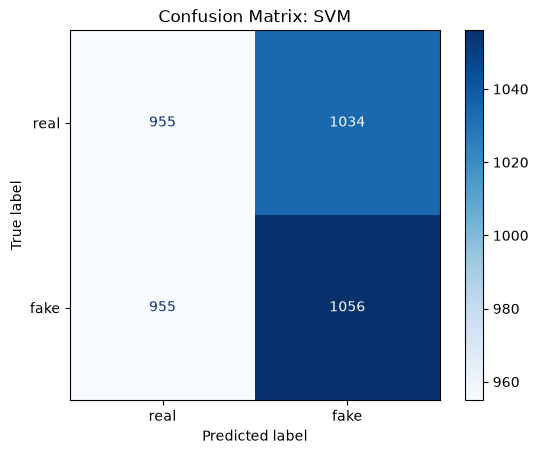

In [10]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["real", "fake"]).plot(cmap="Blues")
plt.title("Confusion Matrix: SVM")
plt.show()

## 8. Top-K Terms and Multicollinearity Check

The full TF-IDF matrix has 867 terms, which is too many to inspect one by one. PFI would have to shuffle every column, PDP/ICE would need hundreds of plots, and an 867 x 867 correlation matrix cannot be read. So we construct the top-K terms (K = 30), the terms most associated with the fake/real label according to a chi-squared score. The scores use training data only, so the test labels never influence which terms are chosen.

Chi-squared is a statistical score that measures how strongly a term is associated with the label. For each term, it compares how much of that term's TF-IDF weight falls in fake articles versus real articles, and checks whether the split differs from what we would expect if the term had nothing to do with the label. A higher score means a stronger association. It does not tell us which direction the term points (fake or real).

We chose chi-squared because it does not depend on any model, so every model can share the same top-K list and be compared fairly. It is also fast, gives the same answer every run, and works with TF-IDF because the weights are never negative. Since TF-IDF weights are continuous rather than counts, the scores are used only to rank terms, not as formal significance tests.

In [11]:
K = 30
top_idx, top_terms, top_scores = select_top_k_terms(X_train, y_train, feature_names, k=K, method="chi2")
pd.DataFrame({"term": top_terms, "chi2_score": top_scores}).head(7)

,term,chi2_score
0,economy,0.576492
1,particular,0.551777
2,significant,0.531097
3,model,0.517952
4,girl,0.503255
5,bring,0.501048
6,reflect,0.499708


The table shows the seven terms with the highest chi-squared scores, meaning the terms most strongly associated with the fake/real label in the training data. The terms (economy, particular, significant, model, girl, bring, reflect) are ordinary words rather than sensational or emotionally charged language, and the scores are low and close together (about 0.50 to 0.58), so no single term stands out. The table also does not say whether a term points toward fake or real.

All 30 terms are used in the analysis below, but only 7 are displayed at a time. Human working memory can hold about 7 ± 2 items at once, so limiting each table and plot to about 7 items lets the reader take it in at a glance without being overloaded.

In [12]:
rng = np.random.RandomState(RANDOM_STATE)

# The SVM is slow to score, so PFI uses 1,000 test articles and PDP/ICE use 200
pfi_idx = rng.choice(X_test_dense.shape[0], size=1000, replace=False)
X_pfi, y_pfi = X_test_dense[pfi_idx].copy(), y_test.iloc[pfi_idx]

pdp_rows = rng.choice(X_test_dense.shape[0], size=200, replace=False)
X_sample = X_test_dense[pdp_rows]

The correlation heatmap checks whether any of the top-K terms move together across the training articles. Each cell shows the correlation between the TF-IDF weights of two terms, where 1 means they rise and fall together, -1 means one rises when the other falls, and 0 means no relationship. We also search for any pair above 0.5. This matters because the result decides which feature-effect technique we use later: PDP changes one term while holding the others fixed, which is only safe if the terms are not dependent on each other, and related terms can also split importance between them, which would distort PFI.

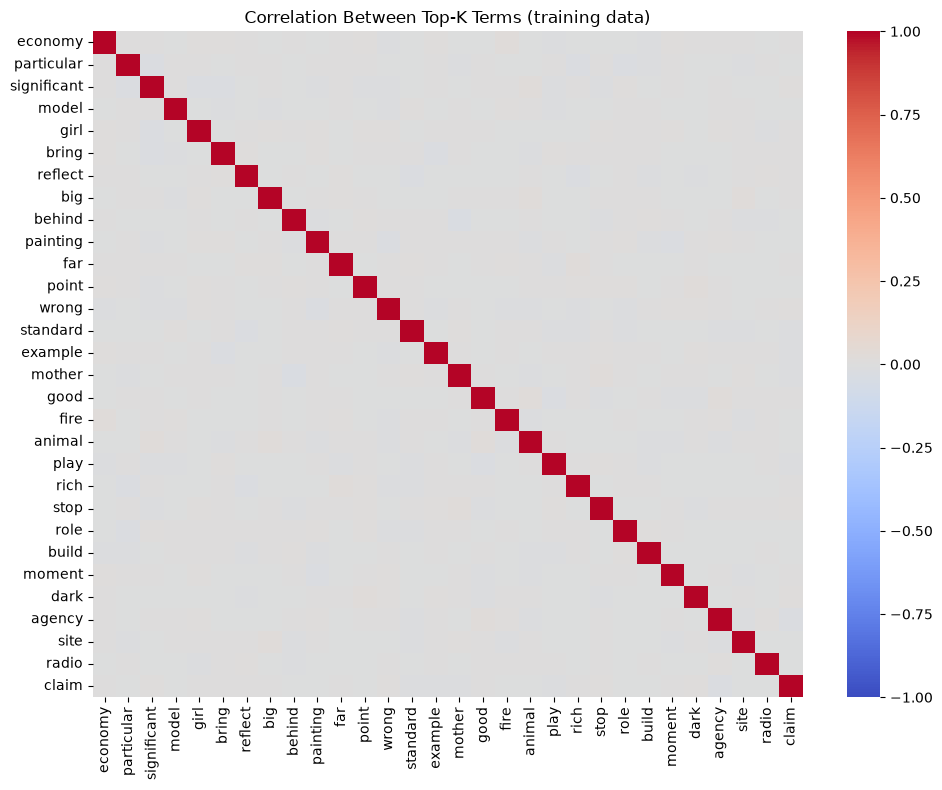

No pairs of terms with |correlation| > 0.5


In [13]:
X_train_topk = pd.DataFrame(X_train[:, top_idx].toarray(), columns=top_terms)
corr = X_train_topk.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Between Top-K Terms (training data)")
plt.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
high_pairs = pairs[pairs.abs() > 0.5]
if high_pairs.empty:
    print("No pairs of terms with |correlation| > 0.5")
else:
    print("Pairs with |correlation| > 0.5:")
    print(high_pairs.sort_values(key=abs, ascending=False))

The heatmap is almost entirely pale gray, meaning the correlations between different terms are close to 0. The only strong cells are the red diagonal, which is each term compared with itself and is always 1. There are no red or blue cells off the diagonal, so none of the top 30 terms tends to appear together with, or instead of, another. The search for pairs of terms with a correlation above 0.5 also found none. This tells us the terms are close to independent of each other, so PDP can be used without creating unrealistic articles, and PFI should not be splitting importance between related terms. This check covers only the top 30 terms and only linear relationships, so it does not rule out every possible dependence, but it gives no reason to switch to ALE.

## 9. Global Importance (PFI)

### 9.1 Permutation Feature Importance (PFI)

Each top-K term is shuffled in the test set and the drop in Fake-class recall is measured. A large drop means the model relies on that term. Because the SVM is slow to score, PFI uses a random sample of 1,000 of the 4,000 test articles and 3 shuffles per term, so its starting recall differs from the recall on the full test set.

In [14]:
def permutation_recall_drop(model, X_dense, y_true, col_indices, n_repeats=3, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)

    def recall_now():
        return recall_score(y_true, (model.decision_function(X_dense) > 0).astype(int), pos_label=1)

    base = recall_now()
    rows = []
    for col in col_indices:
        original = X_dense[:, col].copy()
        drops = []
        for _ in range(n_repeats):
            X_dense[:, col] = rng.permutation(original)
            drops.append(base - recall_now())
        X_dense[:, col] = original
        rows.append((feature_names[col], np.mean(drops), np.std(drops)))
    result = pd.DataFrame(rows, columns=["term", "mean_recall_drop", "std"])
    return base, result.sort_values("mean_recall_drop", ascending=False)

# takes about 8 minutes
base_recall, pfi_df = permutation_recall_drop(svm_model, X_pfi, y_pfi, top_idx)
print(f"Recall before shuffling (1,000-article sample): {base_recall:.4f}")
pfi_df.head(7)

Recall before shuffling (1,000-article sample): 0.5209


,term,mean_recall_drop,std
2,significant,0.015905,0.004295
27,site,0.015905,0.001623
0,economy,0.011928,0.003247
9,painting,0.009940,0.005853
19,play,0.009278,0.002480
25,dark,0.009278,0.004686
8,behind,0.007290,0.003379


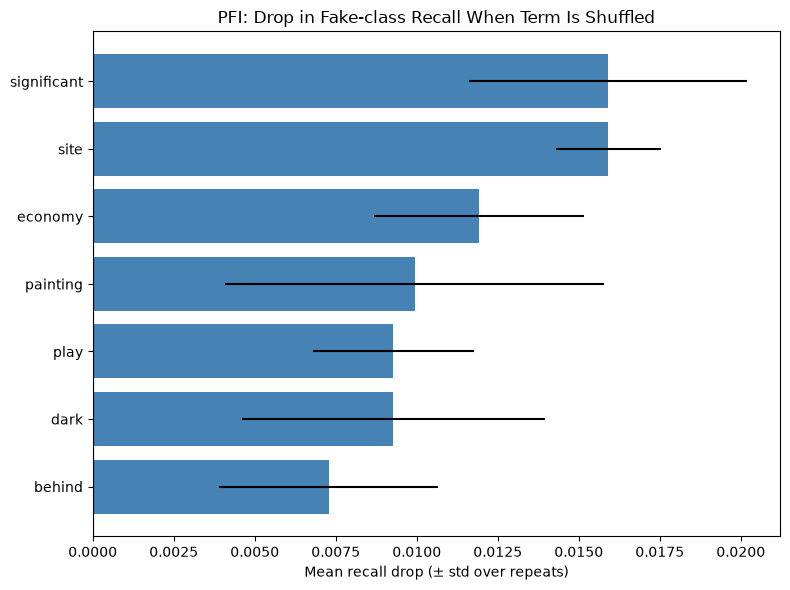

In [15]:
top_pfi = pfi_df.head(7).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top_pfi["term"], top_pfi["mean_recall_drop"], xerr=top_pfi["std"], color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("PFI: Drop in Fake-class Recall When Term Is Shuffled")
plt.xlabel("Mean recall drop (± std over repeats)")
plt.tight_layout()
plt.show()

#### Is PFI measuring anything?

As a check, we shuffle 30 random terms from outside the top 30. If their drops are as large as those of the top terms, the PFI ranking cannot be told apart from noise.

In [16]:
rng_null = np.random.RandomState(RANDOM_STATE)
other_idx = rng_null.choice(np.setdiff1d(np.arange(len(feature_names)), top_idx), 30, replace=False)

# takes about 8 minutes
_, pfi_null = permutation_recall_drop(svm_model, X_pfi, y_pfi, other_idx)
print(pfi_null["mean_recall_drop"].describe())

count    30.000000
mean      0.001149
std       0.003069
min      -0.003976
25%      -0.000663
50%       0.000663
75%       0.002651
max       0.009940
Name: mean_recall_drop, dtype: float64


### 9.2 KernelSHAP (global view)

SHAP values attribute each prediction to individual terms. TreeSHAP only works for tree-based models, so for the SVM we use KernelSHAP, which works with any model by switching terms off and watching how the output changes. Computing it over all 867 terms is slow and gives unstable results, so it is computed only for the 30 top-K terms of each article, with all other terms kept at the article's own values, and the starting value is the model's output for the article with its top-K terms removed. It is computed on a random sample of 100 of the 4,000 test articles, and the values are in decision-value units (positive pushes toward fake, negative toward real).

In [17]:
def kernel_shap_topk(model, x_row, top_idx, nsamples=500):
    # Shapley values for the top-K terms of ONE article; all other terms keep the article's own values
    def f(Z):
        full = np.tile(x_row, (Z.shape[0], 1))
        full[:, top_idx] = Z
        return model.decision_function(full)
    explainer = shap.KernelExplainer(f, np.zeros((1, len(top_idx)), dtype=np.float32))
    values = explainer.shap_values(x_row[top_idx].reshape(1, -1), nsamples=nsamples, silent=True)[0]
    return values, float(explainer.expected_value)

X_shap = X_sample[:100]

# takes about 5 minutes
results = [kernel_shap_topk(svm_model, X_shap[i], top_idx) for i in range(len(X_shap))]
sv_topk = np.array([r[0] for r in results])
base_values = np.array([r[1] for r in results])
print("SHAP values shape:", sv_topk.shape)

SHAP values shape: (100, 30)


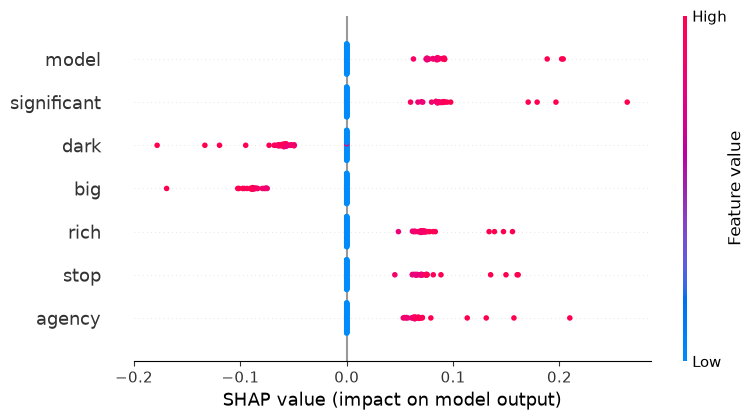

In [18]:
shap.summary_plot(sv_topk, X_shap[:, top_idx], feature_names=list(top_terms), max_display=7)

In [19]:
shap_importance = pd.DataFrame({
    "term": top_terms,
    "mean_abs_shap": np.abs(sv_topk).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

shap_importance.head(7)

,term,mean_abs_shap
3,model,0.025895
2,significant,0.024905
25,dark,0.024709
7,big,0.022733
20,rich,0.021874
21,stop,0.021380
26,agency,0.020819


## 10. Feature Effects (PDP)

As mentioned above, the top terms are not correlated with each other, so changing one term's value while holding the others fixed will not create unrealistic articles. This means PDP can be used here instead of ALE.

PDP shows the model's average decision value (positive means fake) as one term's weight increases, so it tells us which direction each term pushes the prediction and how strongly, on average. It uses a random sample of 200 test articles.

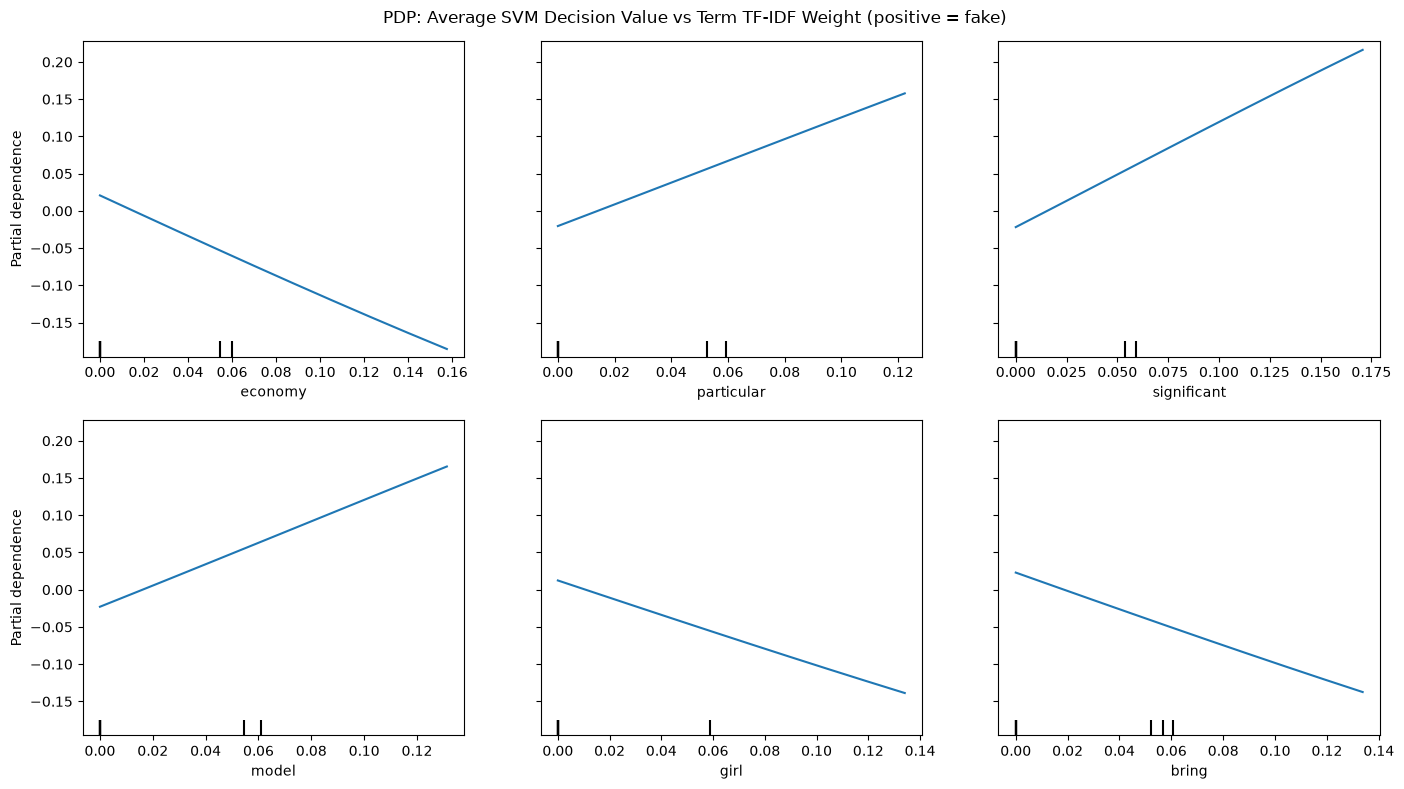

In [20]:
pdp_idx = list(top_idx[:6])

pdp_display = PartialDependenceDisplay.from_estimator(
    svm_model, X_sample,
    features=pdp_idx,
    feature_names=list(feature_names),
    kind="average",
    response_method="decision_function",
    grid_resolution=10,
    percentiles=(0, 1),       # TF-IDF is mostly zeros, so the default 5-95% range would collapse to a single value
    n_cols=3,
    random_state=RANDOM_STATE,
)
pdp_display.figure_.set_size_inches(14, 8)
pdp_display.figure_.suptitle("PDP: Average SVM Decision Value vs Term TF-IDF Weight (positive = fake)")
plt.tight_layout()
plt.show()

## 11. Heterogeneity (ICE)

ICE draws one line per article instead of only the average, so it shows whether a term affects every article the same way, and crossing or diverging lines mean the effect depends on the other terms in the article.

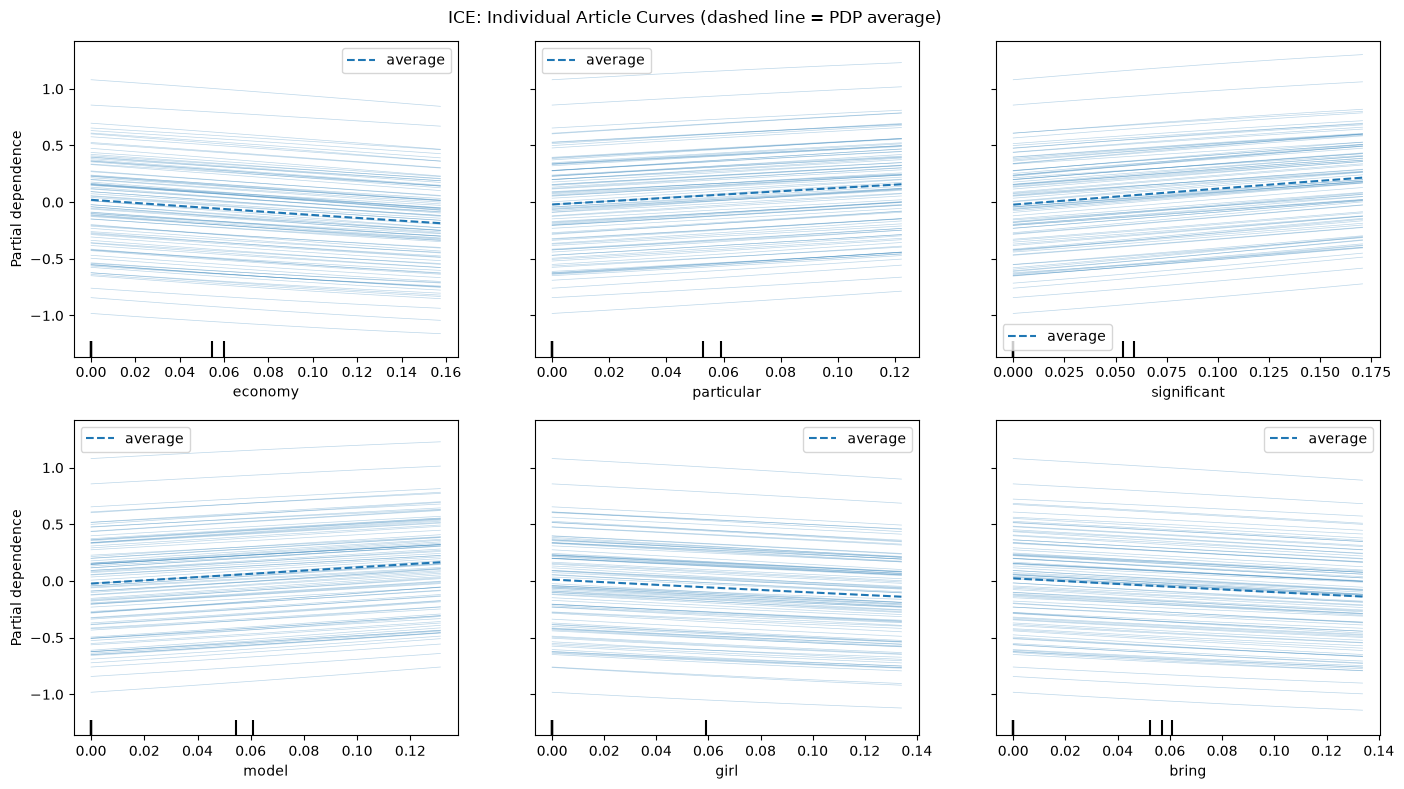

In [21]:
ice_display = PartialDependenceDisplay.from_estimator(
    svm_model, X_sample,
    features=pdp_idx,
    feature_names=list(feature_names),
    kind="both",
    response_method="decision_function",
    subsample=100,
    grid_resolution=10,
    percentiles=(0, 1),
    n_cols=3,
    random_state=RANDOM_STATE,
)
ice_display.figure_.set_size_inches(14, 8)
ice_display.figure_.suptitle("ICE: Individual Article Curves (dashed line = PDP average)")
plt.tight_layout()
plt.show()

### 11.1 Centered ICE

In the ICE plot above, the lines start at different heights, which hides how much each one changes. Centered ICE shifts every line to start at 0, so each line shows only how much the predicted probability changes when the term is added to that article.

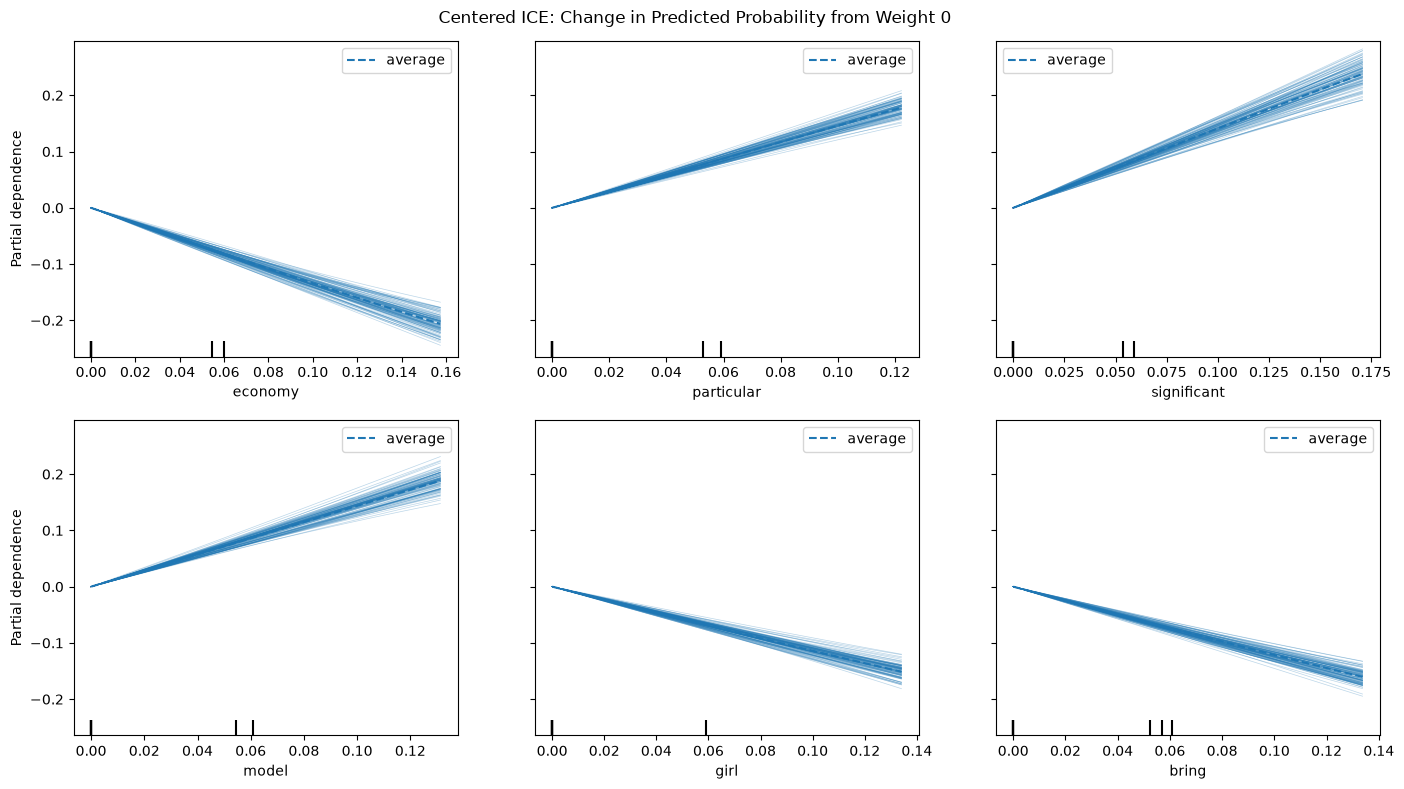

In [22]:
cice_display = PartialDependenceDisplay.from_estimator(
    svm_model, X_sample,
    features=pdp_idx,
    feature_names=list(feature_names),
    kind="both",
    centered=True,
    subsample=100,
    grid_resolution=20,
    percentiles=(0, 1),
    n_cols=3,
    random_state=RANDOM_STATE,
)
cice_display.figure_.set_size_inches(14, 8)
cice_display.figure_.suptitle("Centered ICE: Change in Predicted Probability from Weight 0")
plt.tight_layout()
plt.show()

## 12. Individual Decisions (LIME)

So far we have looked at why the model makes its decisions as a whole (global). Now we pick specific scenarios and ask why the model made this particular decision. We first use SP-LIME to let the data choose a small set of representative articles, and then look at three cases chosen by outcome: a fake article the model caught correctly, a fake article it missed, and a real article it wrongly flagged as fake. LIME is used to show which terms pushed each prediction toward fake or toward real. The score shown for each article is the sigmoid of the SVM's decision value, a probability-like number between 0 and 1 that is not calibrated.

In [23]:
explainer_lime = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)

def predict_proba_text(texts):
    # LIME needs probabilities, so the SVM decision value is passed through a sigmoid
    s = svm_model.decision_function(tfidf.transform(texts).toarray().astype(np.float32))
    p = 1 / (1 + np.exp(-s))
    return np.column_stack([1 - p, p])

test_text = df.loc[y_test.index, "processed_text"].reset_index(drop=True)
y_true_arr = y_test.reset_index(drop=True).to_numpy()
y_pred_arr = np.asarray(y_pred)
proba_fake = 1 / (1 + np.exp(-scores_test))      # probability-like score, not calibrated

tp = np.where((y_true_arr == 1) & (y_pred_arr == 1))[0]
fn = np.where((y_true_arr == 1) & (y_pred_arr == 0))[0]
fp = np.where((y_true_arr == 0) & (y_pred_arr == 1))[0]

cases = {
    "True Positive (fake, caught)":      tp[np.argmax(proba_fake[tp])],
    "False Negative (fake, missed)":     fn[np.argmin(proba_fake[fn])],
    "False Positive (real, flagged)":    fp[np.argmax(proba_fake[fp])],
}

### 12.1 SP-LIME: Choosing Representative Articles

LIME explains one article at a time, so the articles we look at matter. Instead of choosing them by hand, SP-LIME (submodular pick) generates LIME explanations for a pool of 60 test articles and then picks the 5 whose explanations together cover as many of the important words as possible, with as little repetition as possible. The pool is smaller than for the other models because the SVM is slow to score. The pick is based on the words in the explanations, not on the article's category or whether it is fake, so after the pick we check which categories, labels and outcomes were selected.

In [24]:
N_CANDIDATES = 60
N_PICKS = 5

rng_sp = np.random.RandomState(RANDOM_STATE)
cand_idx = rng_sp.choice(len(test_text), size=N_CANDIDATES, replace=False)
cand_text = test_text.iloc[cand_idx].tolist()

# takes about 3 minutes
sp = SubmodularPick(
    explainer_lime, cand_text, predict_proba_text,
    method="full",
    num_exps_desired=N_PICKS,
    num_features=7,
    num_samples=500,
    top_labels=None          # explain the fake class (label 1) for every article
)
sp_idx = cand_idx[sp.V]      # positions of the picked articles in the test set

In [25]:
def outcome(i):
    t, p = int(y_true_arr[i]), int(y_pred_arr[i])
    return {(1, 1): "TP (fake, caught)", (1, 0): "FN (fake, missed)",
            (0, 1): "FP (real, flagged)", (0, 0): "TN (real, correct)"}[(t, p)]

sp_table = pd.DataFrame({
    "category": [df.loc[y_test.index[i], "category"] for i in sp_idx],
    "true_label": ["fake" if y_true_arr[i] == 1 else "real" for i in sp_idx],
    "score": [round(float(proba_fake[i]), 3) for i in sp_idx],
    "outcome": [outcome(i) for i in sp_idx],
})
display(sp_table)

,category,true_label,score,outcome
0,Entertainment,real,0.585,"FP (real, flagged)"
1,Science,real,0.383,"TN (real, correct)"
2,Business,fake,0.541,"TP (fake, caught)"
3,Business,fake,0.437,"FN (fake, missed)"
4,Sports,real,0.600,"FP (real, flagged)"


SP-LIME pick 1 | score = 0.585


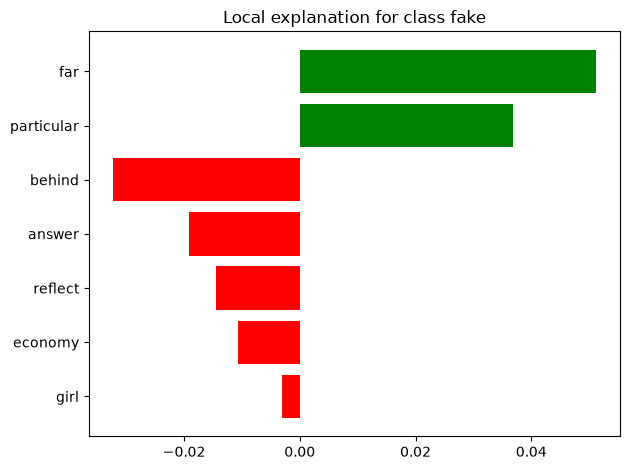

SP-LIME pick 2 | score = 0.383


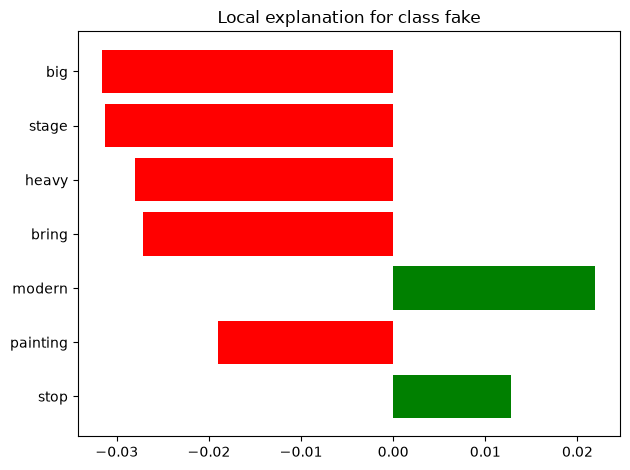

SP-LIME pick 3 | score = 0.541


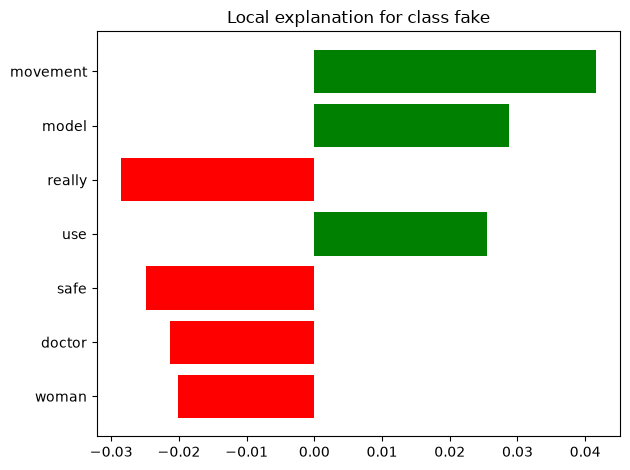

SP-LIME pick 4 | score = 0.437


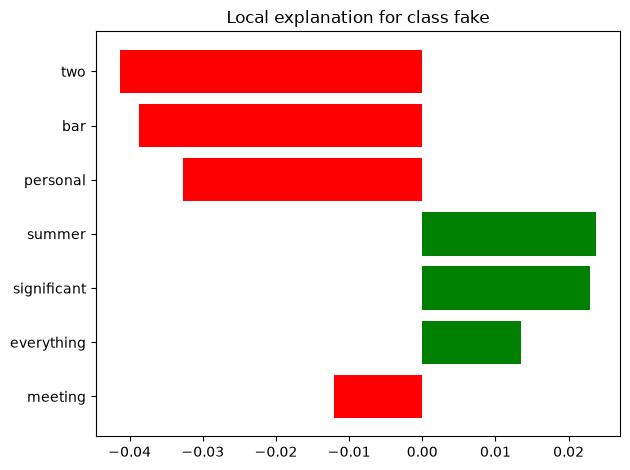

SP-LIME pick 5 | score = 0.600


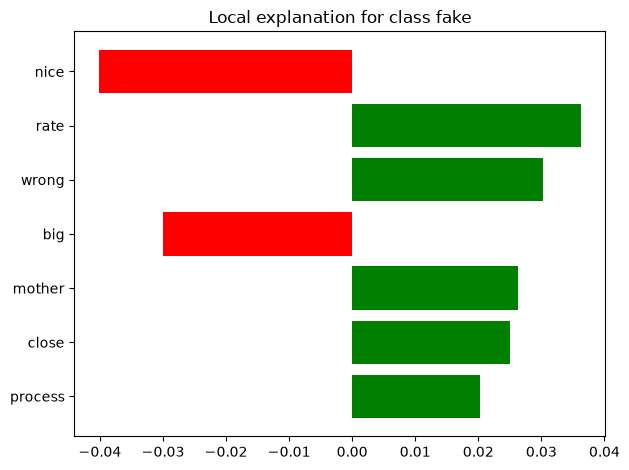

In [26]:
for rank, (exp, i) in enumerate(zip(sp.sp_explanations, sp_idx), start=1):
    print(f"SP-LIME pick {rank} | score = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

### 12.2 LIME: Word-Removal Sanity Checks

LIME removes words from one article and watches how the model's score changes. Three cases are inspected: a correctly caught fake article (TP), a missed fake article (FN), and a real article wrongly flagged as fake (FP). Weights are for the fake class: positive = pushes toward fake.

True Positive (fake, caught) | score = 0.778


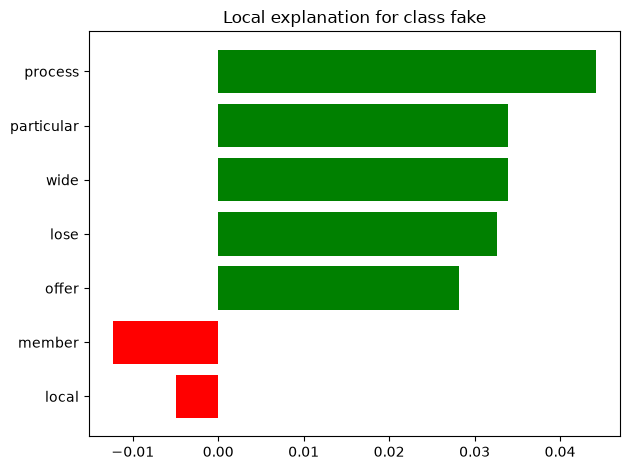

False Negative (fake, missed) | score = 0.208


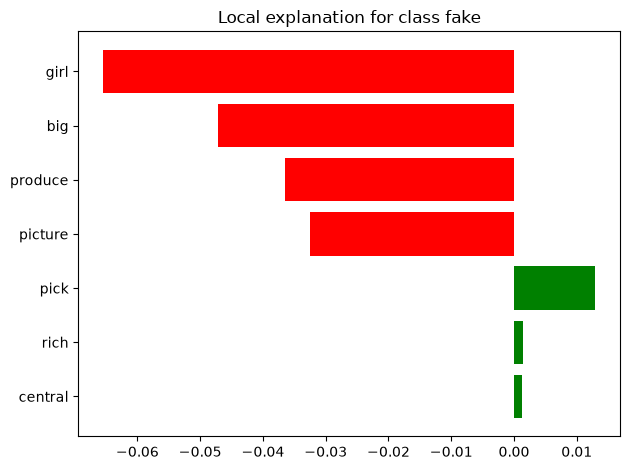

False Positive (real, flagged) | score = 0.829


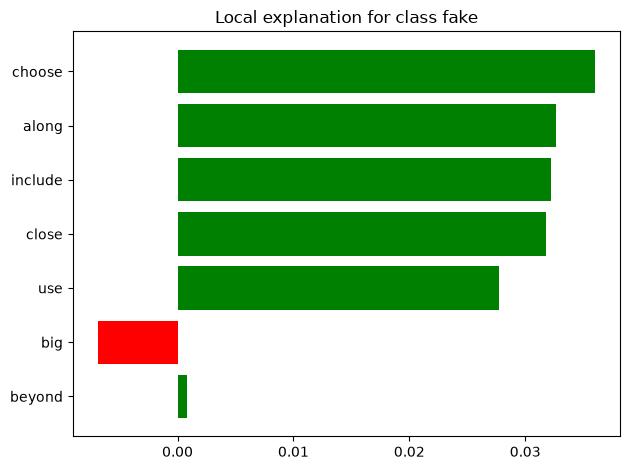

In [27]:
for name, i in cases.items():
    exp = explainer_lime.explain_instance(
        test_text.iloc[i], predict_proba_text,
        num_features=7, num_samples=500, labels=(1,)
    )
    print(f"{name} | score = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

### 12.3 SHAP Waterfall (one article)

LIME explains one prediction by approximating the model around that article, whereas SHAP splits the model's own output into a starting value plus one contribution per top-K term that adds up exactly to the article's decision value, so the waterfall gives an exact term-by-term breakdown for one example article.

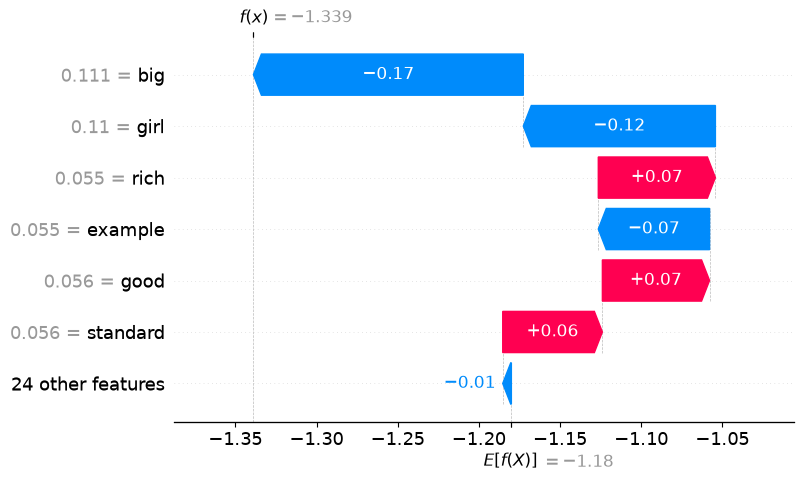

In [29]:
fn_idx = cases["False Negative (fake, missed)"]
x_fn = X_test_dense[fn_idx]                      # one row, 1-D

sv_fn, base_fn = kernel_shap_topk(svm_model, x_fn, top_idx)

shap.plots.waterfall(
    shap.Explanation(
        values=sv_fn, base_values=base_fn,
        data=x_fn[top_idx], feature_names=list(top_terms)
    ),
    max_display=7
)

## 13. Summary